# 08 Robustness and amount of data: what happens with noisy signals, drift, less training data, and a few past samples as input?

**Question (the bonus items on noise and drift, amount of data and time context).** (1) What is in the noisy file the organizers gave us,
and is there drift in it? (2) How much worse is a network trained on clean data when the input is noisy or drifting, and what does a network trained with noise cost
and gain? (3) How many training discharges do we need? (4) Does giving the network the last three samples instead of one help?

This notebook is **data free**. It parses the numbers out of the aggregate files committed under `results/`
(`ipp1-data-checks.md`, `ipp1-robustness-findings.md`, `ipp1-final.md`, `ipp1-time.json`, `ipp1-latency.json`); no IPP row is read and nothing is trained,
so it runs top to bottom on a clean checkout in a few seconds (needs `numpy pandas matplotlib`). The measurements were made by the scripts in `analysis/`
on the confidential data; each table names its protocol.

| name | what it is | used for |
|---|---|---|
| **R, 5 folds** | baseline network (256-256-128, 60 epochs), 5 folds split by whole discharge, mean over folds, 119 training discharges per fold; noise and drift are generated by us unless the **provided noisy file** is named | sections 1, 2, 4, 5 |
| **O, out-of-fold** | the same baseline's pooled out-of-fold predictions on clean inputs, on the provided noisy inputs, and from a network trained with noise and drift (`ipp1-time.json`) | section 3 |
| **L, set aside** | models trained on 119 development discharges, scored once per final model on 30 discharges kept aside; one seed (`ipp1-final.md`) | section 2.1 |

Units: mm for positions, kA for the plasma current, elongation without unit. Errors are mean absolute differences (MAE) from the reference reconstruction (the institute's equilibrium reconstruction that gives the labels, not an independent measurement of the plasma). **Scope:** everything here is for the
*baseline network*; the noise is white noise provided by the organizers (the drift is our own synthetic model); stability statements are conditional on the kind of input.

In [1]:
import re, json, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

# This notebook reads only files committed under results/ (tables, json, png); it needs no IPP data and no training.
here = Path.cwd().resolve()
repo = next((p for p in [here, *here.parents] if (p / "results" / "ipp1-final.md").exists()), None)
if repo is None:
    raise SystemExit("Run from inside the repository: results/ipp1-final.md was not found")
RES = repo / "results"
READ = set()  # every results file this notebook opens, checked against `git ls-files` at the end


def read(name):
    READ.add(name)
    return (RES / name).read_text()


def num(x):
    """First number in a cell: '44.2%' -> 44.2, '1.2 [0.9, 1.4]' -> 1.2, '0.53 to 1.10 (2.1x)' -> 0.53, 'n/a' -> nan."""
    m = re.search(r"-?\d+(?:\.\d+)?(?:e[+-]?\d+)?", str(x).replace(",", ""))
    return float(m.group()) if m else np.nan


def md_tables(name):
    """All pipe tables of a results markdown file as (nearest heading above, DataFrame of strings)."""
    out, heading, cur = [], "", None
    for line in read(name).splitlines():
        if line.startswith("#"):
            heading, cur = line.lstrip("# ").strip(), None
        elif line.startswith("|"):
            cells = [c.strip() for c in line.strip().strip("|").split("|")]
            if cur is None:
                cur = {"heading": heading, "header": cells, "rows": []}
                out.append(cur)
            elif not set("".join(cells)) <= set("-: "):
                cur["rows"].append(cells)
        else:
            cur = None
    return [(t["heading"], pd.DataFrame(t["rows"], columns=t["header"])) for t in out]


def table(name, heading=None, has=None, nth=0):
    """The nth table whose heading starts with `heading` and whose header contains every column in `has`."""
    hits = [df for h, df in md_tables(name)
            if (heading is None or h.startswith(heading)) and all(c in df.columns for c in (has or []))]
    if len(hits) <= nth:
        raise KeyError(f"{name}: no table for heading={heading!r} has={has!r}")
    return hits[nth]


def numeric(df, text=("target", "unit")):
    """Index by the first column and turn every other column into floats (text columns kept as strings)."""
    df = df.copy()
    if "unit" in df.columns:
        df["unit"] = df["unit"].replace("", "-")  # dimensionless targets: the results files leave the cell empty
    for c in df.columns[1:]:
        if c not in text:
            df[c] = df[c].map(num).astype(float)
    return df.set_index(df.columns[0])


def section(name, heading):
    """Lines of the `## heading...` section (up to the next `## `), as written in the results file."""
    lines, on = [], False
    for line in read(name).splitlines():
        if line.startswith("## "):
            on = line[3:].startswith(heading)
            continue
        if on:
            lines.append(line)
    if not lines:
        raise KeyError(f"{name}: no section {heading!r}")
    return "\n".join(lines).strip()


def show(df, proto, fmt="{:.3g}"):
    """Print a table with the protocol it was measured under right above it."""
    print("Protocol:", proto)
    print(df.to_string(float_format=lambda v: fmt.format(v)))
    print()


def quote(text, source):
    display(Markdown(f"*Quoted from `results/{source}`:*\n\n" + text))


def tracked_check():
    """True when every results file opened above is under git version control (not a local scratch file)."""
    out = subprocess.run(["git", "-C", str(repo), "ls-files", "results"], capture_output=True, text=True)
    tracked = {Path(p).name for p in out.stdout.split()}
    missing = sorted(f for f in READ if f not in tracked)
    return missing, len(READ), bool(tracked)


print("repository:", repo.name, "| results folder:", RES.relative_to(repo))

repository: hackathon-cloud | results folder: results


## 1. What is in the noisy file? White noise, no drift

`equil_data_noisy.csv` is the clean file with noise added. `ipp1-data-checks.md` measures its structure: the noise divided by the standard deviation of the
signal, its correlation with time inside a discharge (a linear drift would show here) and its lag-1 autocorrelation (white noise is about 0).

*Quoted from `results/ipp1-data-checks.md`:*

- Noise standard deviation over the standard deviation of the signal: IPR coils median 0.158, flux loops median 0.090, overall range 0.086 to 0.167.
- Mean absolute correlation of the noise with time inside a discharge (a linear drift would show here): 0.049.
- Mean lag-1 autocorrelation of the noise inside a discharge (white noise is about 0): -0.004.
- Reading: white noise, no measurable drift; every drift result of ours is synthetic.

coil noise 0.158 and flux loop noise 0.09 of the signal SD (range 0.086 to 0.167); correlation with time 0.049; lag-1 autocorrelation -0.004 (the robustness report quotes about -0.005 from a second measurement)


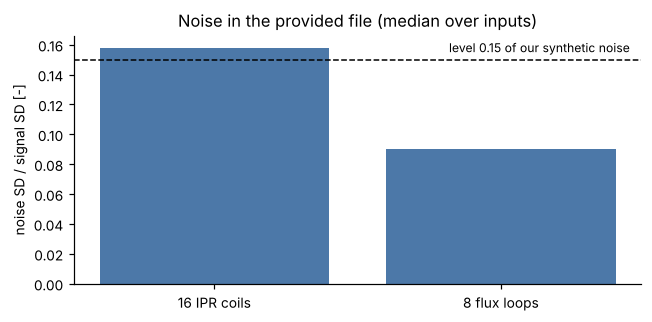

**Reading.** The provided noisy file is white noise (lag-1 autocorrelation -0.004, about 0) with no measurable drift (mean absolute correlation with time is the small value that white noise gives, 0.049). It differs from the clean file by 0.155 of an input SD (median). Synthetic noise of level 0.15 gives the same errors as the provided file (radial axis 10.4 mm against 10.2 mm), so it stands in for the provided file. It says nothing about the noise of real probes: the provided noise looks like noise added in proportion to each input's standard deviation (the ratio stays between 0.086 and 0.167; our inference, not confirmed) and may be larger than real probe noise (to be checked with the institute), so these errors are a stress test, not an expected operating accuracy. **Every drift result below is synthetic**: a drift of our own design, not a measured drift of the real diagnostics.

In [2]:
F_CHK, F_ROB = "ipp1-data-checks.md", "ipp1-robustness-findings.md"
noise_txt = section(F_CHK, "Structure of the noise")
quote(noise_txt, F_CHK)
m = re.search(r"IPR coils median (\d+\.\d+), flux loops median (\d+\.\d+), overall range (\d+\.\d+) to (\d+\.\d+)", noise_txt)
coil_med, fl_med, lo, hi = map(float, m.groups())
corr_time = float(re.search(r"correlation of the noise with time.*?: (-?\d+\.\d+)\.", noise_txt).group(1))
lag1 = float(re.search(r"lag-1 autocorrelation.*?: (-?\d+\.\d+)\.", noise_txt).group(1))
rob = read(F_ROB)
lag1_rob = float(re.search(r"lag 1 autocorrelation of\s+the noise about (-?\d+\.\d+)", rob).group(1))
diff_med = float(re.search(r"differs\s+from the clean one by (\d+\.\d+) of an input SD", rob).group(1))
syn, prov = map(float, re.search(r"R axis (\d+\.\d+) mm\s+synthetic against (\d+\.\d+) mm provided", rob).groups())
print(f"coil noise {coil_med} and flux loop noise {fl_med} of the signal SD (range {lo} to {hi}); correlation with time {corr_time}; lag-1 autocorrelation {lag1} "
      f"(the robustness report quotes about {lag1_rob} from a second measurement)")

fig, ax = plt.subplots(figsize=(6, 3)); ax.bar(["16 IPR coils", "8 flux loops"], [coil_med, fl_med], color="#4c78a8")
ax.axhline(0.15, color="k", ls="--", lw=1); ax.text(1.45, 0.155, "level 0.15 of our synthetic noise", ha="right", fontsize=8)
ax.set_ylabel("noise SD / signal SD [-]"); ax.set_title("Noise in the provided file (median over inputs)"); plt.tight_layout(); plt.show()
display(Markdown(
    f"**Reading.** The provided noisy file is white noise (lag-1 autocorrelation {lag1}, about 0) with no measurable drift (mean absolute correlation with time is the small value that white noise gives, "
    f"{corr_time:.3f}). It differs from the clean file by {diff_med} of an input SD (median). "
    f"Synthetic noise of level 0.15 gives the same errors as the provided file (radial axis {syn} mm against {prov} mm), so it stands in for the provided file. "
    f"It says nothing about the noise of real probes: the provided noise looks like noise added in proportion to each input's standard deviation (the ratio stays between {lo} and {hi}; our inference, not confirmed) "
    f"and may be larger than real probe noise (to be checked with the institute), so these errors are a stress test, not an expected operating accuracy. "
    f"**Every drift result below is synthetic**: a drift of our own design, not a measured drift of the real diagnostics."))

## 2. Noise and drift: trained on clean, trained on noisy, trained with augmentation (protocol R, 5 folds)

Synthetic noise is Gaussian, per row, with a standard deviation given as a fraction of each input's training standard deviation. Drift is `c * t`: an independent Gaussian
slope per discharge and coil (`c` is the standard deviation of the slope), `t` the relative time of the discharge; the drift runs also add noise 0.15.
*Augmented* means trained on the clean rows plus one corrupted copy (noise 0.15, drift 0.15).

Every discharge reaches the same total drift at its end whatever its length; a real integrator offset grows with absolute time. Calibration errors, a failed or saturated probe, pickup from the coil currents and thermal drift were not tested.

Protocol: R: baseline network 256-256-128, 60 epochs, 5 folds split by discharge, MAE on held-out discharges, mean over folds; noise and drift synthetic unless 'provided noisy' (`ipp1-robustness-findings.md`)
                                                             R axis [mm]  Z axis [mm]  elongation [-]  limiter Z [mm]  is_limited accuracy [%]
trained on, tested on                                                                                                                         
clean, clean                                                        0.38         0.39          0.0057            22.2                     99.3
clean, provided noisy                                               10.2         4.12           0.032            62.6                     98.6
clean, synthetic noise 0.30                                         20.8          8.5           0.069             110                     95.7
clean, synthetic noise 0.15 + synthetic drift 0.30                  15.1    

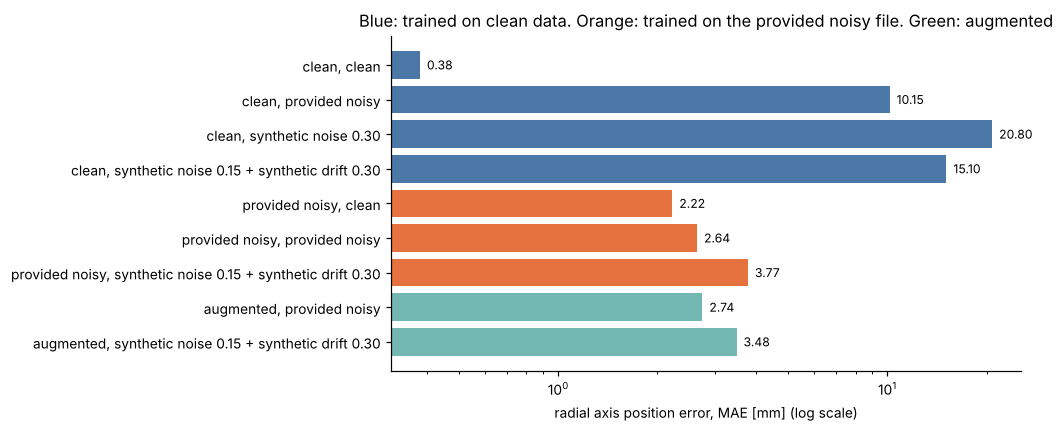

In [3]:
P_R = ("R: baseline network 256-256-128, 60 epochs, 5 folds split by discharge, MAE on held-out discharges, mean over folds; "
       "noise and drift synthetic unless 'provided noisy' (`ipp1-robustness-findings.md`)")
nd = numeric(table(F_ROB, "1. Noise and drift"), text=())
nd.index.name = "trained on, tested on"
def synth(s):  # make clear that drift (and the added noise) are ours, not in the provided file
    return s.replace("noise 0.", "synthetic noise 0.").replace("drift 0.", "synthetic drift 0.")


nd.columns = ["R axis [mm]", "Z axis [mm]", "elongation [-]", "limiter Z [mm]", "is_limited accuracy [%]"]
show(nd.rename(index=synth), P_R)

fig, ax = plt.subplots(figsize=(9.5, 4)); names = list(nd.index)
colors = ["#4c78a8" if n.startswith("clean") else "#e6733f" if n.startswith("provided") else "#72b7b2" for n in names]
ax.barh([synth(n) for n in names], nd["R axis [mm]"], color=colors); ax.set_xscale("log"); ax.invert_yaxis()
for i, v in enumerate(nd["R axis [mm]"]): ax.text(v * 1.05, i, f"{v:.2f}", va="center", fontsize=8)
ax.set_xlabel("radial axis position error, MAE [mm] (log scale)")
ax.set_title("Blue: trained on clean data. Orange: trained on the provided noisy file. Green: augmented")
plt.tight_layout(); plt.show()

In [4]:
cc, cn = nd.loc["clean, clean", "R axis [mm]"], nd.loc["clean, provided noisy", "R axis [mm]"]
nn, nc = nd.loc["provided noisy, provided noisy", "R axis [mm]"], nd.loc["provided noisy, clean", "R axis [mm]"]
drift_h = nd.loc["provided noisy, noise 0.15 + drift 0.30", "R axis [mm]"] - nn
drift_c = nd.loc["clean, noise 0.15 + drift 0.30", "R axis [mm]"] - syn
display(Markdown(
    f"**Reading (radial axis, mm).** A network trained on clean data agrees closely with the reference reconstruction and is fragile: {cc:.2f} on clean inputs, **{cn:.1f}** on the provided noisy inputs ({cn/cc:.0f} times larger). "
    f"Trained on the noisy file it gives **{nn:.2f}** on noisy inputs, but {nc:.2f} on clean inputs: robustness is paid for with a worse agreement on clean inputs. "
    f"A synthetic drift of slope SD 0.3 on top of noise 0.15 adds {drift_h:.1f} mm for the network trained on the noisy file and {drift_c:.1f} mm for the clean-trained network "
    f"(noise 0.15 alone gives {syn} mm there, `{F_ROB}`). The amplitudes of drift and noise are not comparable, so we do not say drift hurts less than noise. "
    f"Our augmentation is not better than training on the provided noisy file ({nd.loc['augmented, provided noisy','R axis [mm]']:.2f} against {nn:.2f} mm, a difference the report does not count as established); "
    f"its use is that it needs no noisy file."))

**Reading (radial axis, mm).** A network trained on clean data agrees closely with the reference reconstruction and is fragile: 0.38 on clean inputs, **10.2** on the provided noisy inputs (27 times larger). Trained on the noisy file it gives **2.64** on noisy inputs, but 2.22 on clean inputs: robustness is paid for with a worse agreement on clean inputs. A synthetic drift of slope SD 0.3 on top of noise 0.15 adds 1.1 mm for the network trained on the noisy file and 4.7 mm for the clean-trained network (noise 0.15 alone gives 10.4 mm there, `ipp1-robustness-findings.md`). The amplitudes of drift and noise are not comparable, so we do not say drift hurts less than noise. Our augmentation is not better than training on the provided noisy file (2.74 against 2.64 mm, a difference the report does not count as established); its use is that it needs no noisy file.

### 2.1 The same trade on the 30 discharges kept aside (protocol L)

`ipp1-final.md` compares the plain baseline, the baseline trained with noise and drift (`augmented`), and the shipped candidate recipe (difference inputs, ridge current, gated limiter network),
each on clean inputs and on the provided noisy file. The set of 30 discharges is **easier than the development average** (see notebook 07, section 4.1), so these
numbers are lower than the cross-validation ones above and are not comparable with them.

Protocol: L: trained on 119 development discharges, scored on 30 kept-aside discharges (8,761 rows), one seed (`ipp1-final.md`); MAE except the last column
                                      plasma_current [kA]  R_mag_axis [mm]  Z_mag_axis [mm]  R_x_point [mm]  R_limiter [mm]  mean nRMSE (16)
recipe                        inputs                                                                                                        
baseline MLP                  clean                   1.2            0.307            0.321           0.161            10.6           0.0803
                              noisy                  5.63             9.16             3.82            4.35            48.9           0.4923
baseline, noise-trained       clean                  1.91             1.56            0.837            1.56            18.6           0.1998
                              noisy                  4.65             2.38             1.86            2.47            25.8           0.289

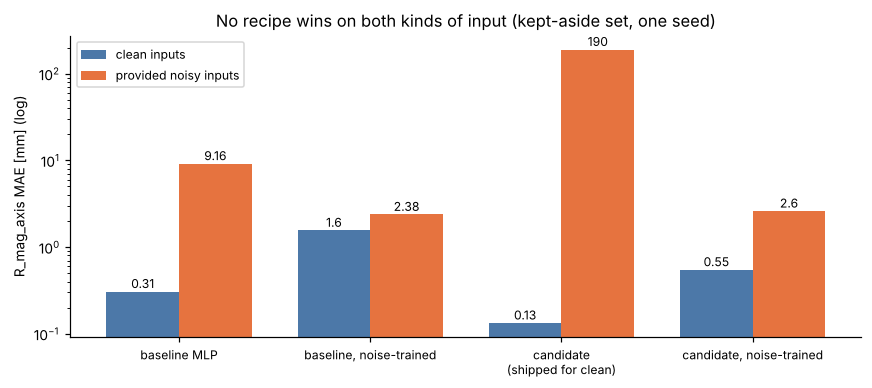

*Quoted from `results/ipp1-final.md`:*

- **clean inputs: candidate, plain** (`cand`): lowest mean nRMSE over the 16 targets in the development cross-validation (baseline MLP 0.1228, baseline MLP, augmented (extra) 0.2385, candidate, plain 0.0912, candidate, augmented 0.1705).
- **noisy inputs: baseline MLP, augmented (extra)** (`base_aug`): lowest mean nRMSE over the 16 targets in the development cross-validation (baseline MLP 0.5267, baseline MLP, augmented (extra) 0.3129, candidate, plain 12.4320, candidate, augmented 0.3321).
- Locked-set check of that choice: mean nRMSE over 16 targets, clean: baseline MLP 0.0803, baseline MLP, augmented (extra) 0.1998, candidate, plain 0.0590, candidate, augmented 0.1108; noisy: baseline MLP 0.4923, baseline MLP, augmented (extra) 0.2891, candidate, plain 12.0304, candidate, augmented 0.3159.

**Reading.** On noisy inputs the noise-trained baseline gives 2.38 mm on the radial axis against 9.16 mm for the plain baseline; the plain candidate collapses (190 mm, mean nRMSE 12.0) because its neighboring-coil differences amplify noise. On clean inputs the noise-trained baseline is 5.1 times worse than the plain baseline. A deployment therefore needs to know which kind of input it gets; there is no single model that wins in both cases.

In [5]:
F_FIN = "ipp1-final.md"
P_L = "L: trained on 119 development discharges, scored on 30 kept-aside discharges (8,761 rows), one seed (`ipp1-final.md`)"
recipes = {"baseline MLP": "baseline MLP", "baseline MLP, augmented (extra)": "baseline, noise-trained", "candidate, plain": "candidate (shipped for clean)", "candidate, augmented": "candidate, noise-trained"}
tg = ["plasma_current", "R_mag_axis", "Z_mag_axis", "R_x_point", "R_limiter"]
res = {}
for key, short in recipes.items():
    for kind in ("clean", "noisy"):
        d = numeric(table(F_FIN, f"{key}, {kind} inputs"))
        head = [h for h, _ in md_tables(F_FIN) if h.startswith(f"{key}, {kind} inputs")][0]
        res[(short, kind)] = {t: d.loc[t, "MAE"] for t in tg} | {"mean nRMSE (16)": float(re.search(r"mean nRMSE over 16 targets (\d+\.\d+)", head).group(1))}
lock = pd.DataFrame(res).T
lock.index.names = ["recipe", "inputs"]
lock.columns = ["plasma_current [kA]", "R_mag_axis [mm]", "Z_mag_axis [mm]", "R_x_point [mm]", "R_limiter [mm]", "mean nRMSE (16)"]
show(lock, P_L + "; MAE except the last column", fmt="{:.4g}")

fig, ax = plt.subplots(figsize=(8, 3.6)); x = np.arange(len(recipes)); w = 0.38
vals_c = [lock.loc[(r, "clean"), "R_mag_axis [mm]"] for r in recipes.values()]; vals_n = [lock.loc[(r, "noisy"), "R_mag_axis [mm]"] for r in recipes.values()]
ax.bar(x - w/2, vals_c, w, label="clean inputs", color="#4c78a8"); ax.bar(x + w/2, vals_n, w, label="provided noisy inputs", color="#e6733f")
ax.set_yscale("log"); ax.set_xticks(x); ax.set_xticklabels([r.replace(" (", "\n(") for r in recipes.values()], fontsize=8)
for xi, v in zip(x - w/2, vals_c): ax.text(xi, v * 1.1, f"{v:.2g}", ha="center", fontsize=8)
for xi, v in zip(x + w/2, vals_n): ax.text(xi, v * 1.1, f"{v:.3g}", ha="center", fontsize=8)
ax.set_ylabel("R_mag_axis MAE [mm] (log)"); ax.set_title("No recipe wins on both kinds of input (kept-aside set, one seed)"); ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

quote(section(F_FIN, "Which recipe to ship"), F_FIN)
b, ba, cp = lock.loc[("baseline MLP", "noisy"), "R_mag_axis [mm]"], lock.loc[("baseline, noise-trained", "noisy"), "R_mag_axis [mm]"], lock.loc[("candidate (shipped for clean)", "noisy"), "R_mag_axis [mm]"]
display(Markdown(
    f"**Reading.** On noisy inputs the noise-trained baseline gives {ba:.2f} mm on the radial axis against {b:.2f} mm for the plain baseline; the plain candidate collapses ({cp:.0f} mm, "
    f"mean nRMSE {lock.loc[('candidate (shipped for clean)','noisy'),'mean nRMSE (16)']:.1f}) because its neighboring-coil differences amplify noise. "
    f"On clean inputs the noise-trained baseline is {lock.loc[('baseline, noise-trained','clean'),'R_mag_axis [mm]']/lock.loc[('baseline MLP','clean'),'R_mag_axis [mm]']:.1f} times worse than the plain baseline. "
    f"A deployment therefore needs to know which kind of input it gets; there is no single model that wins in both cases."))

## 3. Stability over time, conditional on the kind of input (protocol O)

`ipp1-time.json` holds the out-of-fold predictions' stability measures. The **jitter ratio** is the RMS row-to-row change of the prediction divided by the same for the reference values.
It is amplitude weighted: it stays near 1 whenever the output is smooth because its input is smooth, so it is a statement about clean inputs and **not** a noise measure.
The three columns below are the plain network on clean inputs, the plain network on the provided noisy inputs, and the network trained with noise and drift (called "hardened" in the report) on noisy inputs.

Protocol: O: baseline network, out-of-fold over 149 discharges; hardened = trained with noise 0.15 and drift 0.15 (`ipp1-time.json`, `ipp1-time.md`); jitter ratio = RMS row-to-row change of the estimate / of the reference values
                clean inputs, trained clean  noisy inputs, trained clean  noisy inputs, trained with noise and drift
R_mag_axis                             0.97                         8.42                                        1.71
Z_mag_axis                             1.06                         3.25                                        1.65
elongation                             1.03                         4.42                                        2.45
plasma_current                         1.07                         4.47                                        3.27
R_x_point                              1.00                        17.84                                        6.76



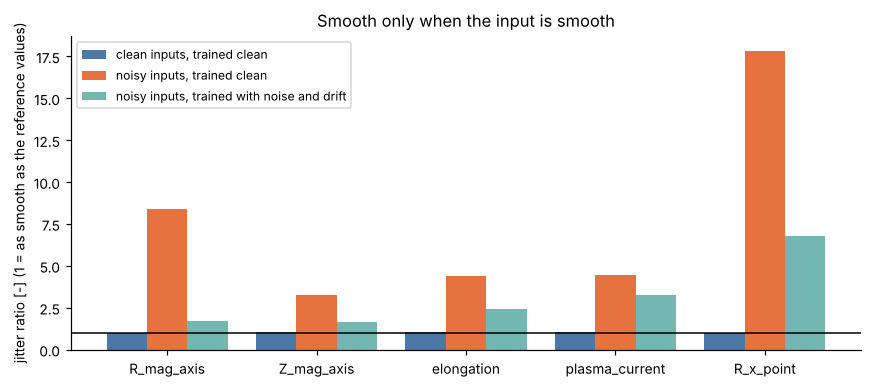

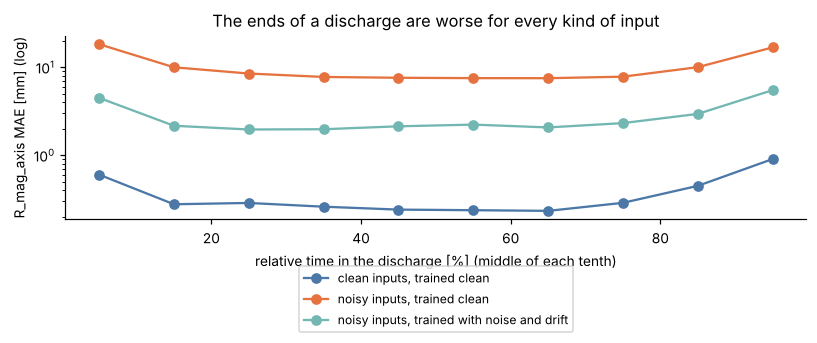

**Reading (conditional).** On clean inputs the output varies as the reference values do: jitter ratio 0.97 to 1.07 for the 5 targets shown. This is not a statement about noisy signals: with the provided noisy inputs the clean-trained network varies 8.4 times (radial axis) and 3.3 times (vertical axis) more than the reference values, and 1.71 and 1.65 times after training with noise and drift.

In [6]:
tj = json.loads(read("ipp1-time.json"))
P_O = ("O: baseline network, out-of-fold over 149 discharges; hardened = trained with noise 0.15 and drift 0.15 (`ipp1-time.json`, `ipp1-time.md`)")
tt = ["R_mag_axis", "Z_mag_axis", "elongation", "plasma_current", "R_x_point"]
jit = pd.DataFrame({
    "clean inputs, trained clean": {t: tj["jitter_ratio"][t] for t in tt},
    "noisy inputs, trained clean": {t: tj["noisy"]["clean_on_noisy"]["jitter_ratio"][t] for t in tt},
    "noisy inputs, trained with noise and drift": {t: tj["noisy"]["hardened_on_noisy"]["jitter_ratio"][t] for t in tt}})
show(jit, P_O + "; jitter ratio = RMS row-to-row change of the estimate / of the reference values", fmt="{:.2f}")
fig, ax = plt.subplots(figsize=(8, 3.6)); x = np.arange(len(jit)); w = 0.27
for i, (c, colr) in enumerate(zip(jit.columns, ["#4c78a8", "#e6733f", "#72b7b2"])): ax.bar(x + (i - 1) * w, jit[c], w, label=c, color=colr)
ax.axhline(1, color="k", lw=1); ax.set_xticks(x); ax.set_xticklabels(jit.index); ax.set_ylabel("jitter ratio [-] (1 = as smooth as the reference values)")
ax.set_title("Smooth only when the input is smooth"); ax.legend(fontsize=8, loc="upper left"); plt.tight_layout(); plt.show()

dec = {k: np.array(v["mae_by_time_decile"]["R_mag_axis"]) for k, v in {"clean inputs, trained clean": tj, "noisy inputs, trained clean": tj["noisy"]["clean_on_noisy"], "noisy inputs, trained with noise and drift": tj["noisy"]["hardened_on_noisy"]}.items()}
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for (k, v), colr in zip(dec.items(), ["#4c78a8", "#e6733f", "#72b7b2"]): ax.plot(np.arange(1, 11) * 10 - 5, v, marker="o", label=k, color=colr)
ax.set_yscale("log"); ax.set_xlabel("relative time in the discharge [%] (middle of each tenth)"); ax.set_ylabel("R_mag_axis MAE [mm] (log)")
ax.set_title("The ends of a discharge are worse for every kind of input"); ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=1); plt.tight_layout(); plt.show()
display(Markdown(
    f"**Reading (conditional).** On clean inputs the output varies as the reference values do: jitter ratio {jit.iloc[:,0].min():.2f} to {jit.iloc[:,0].max():.2f} for the {len(tt)} targets shown. "
    f"This is not a statement about noisy signals: with the provided noisy inputs the clean-trained network varies {jit.loc['R_mag_axis'].iloc[1]:.1f} times (radial axis) and "
    f"{jit.loc['Z_mag_axis'].iloc[1]:.1f} times (vertical axis) more than the reference values, and {jit.loc['R_mag_axis'].iloc[2]:.2f} and {jit.loc['Z_mag_axis'].iloc[2]:.2f} times after training with noise and drift."))

## 4. Amount of training data (protocol R, 5 folds)

Nested subsets of the training discharges (on average 6, 12, 30, 60 and 119 discharges; 1.7 thousand to 34 thousand rows), the same test folds. **The number of epochs is fixed at 60**, so
smaller sets also get fewer optimizer updates: part of the improvement with more data is more training steps, and the slope is overstated.

Protocol: R: baseline network 256-256-128, 60 epochs, 5 folds split by discharge, MAE on held-out discharges, mean over folds; noise and drift synthetic unless 'provided noisy' (`ipp1-robustness-findings.md`); test folds identical for every row, fixed 60 epochs
                     R axis [mm]  Z axis [mm]  X point R [mm]  elongation [-]  limiter Z [mm]  is_limited accuracy [%]
training discharges                                                                                                   
6                            7.3          4.7             3.9           0.145            73.7                     94.9
12                           6.9          2.8             1.5           0.075            55.6                     96.8
30                          1.47         0.95            0.75          0.0116            34.3                     98.9
60                          0.83          0.6            0.38          0.0086            28.8                     99.1
119                     

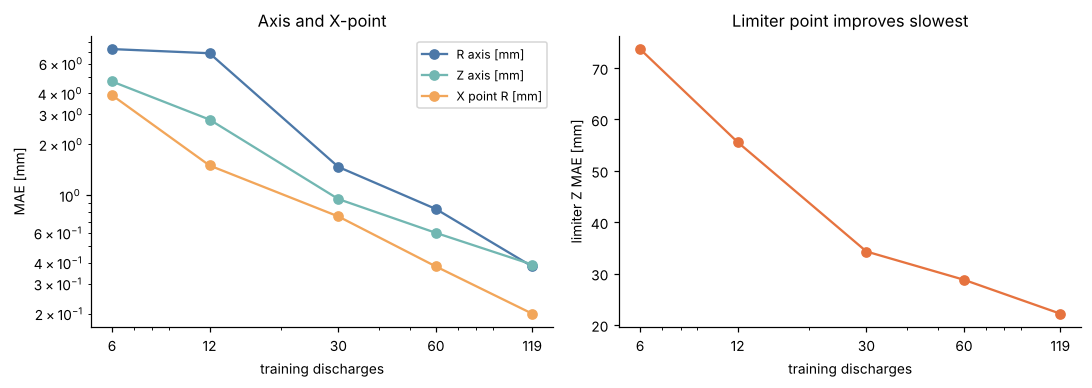

**Reading.** With 30 training discharges the radial axis error is 1.47 mm and the vertical 0.95 mm; with all 119 it is 0.38 and 0.39 mm. From 30 to 119 discharges the radial error falls to 0.56 of its value at the first doubling and 0.46 at the second, roughly a halving per doubling, but with a fixed 60 epochs, so the slope is overstated. Below 30 discharges the error is several millimetres (7.3 mm at 6, 6.9 mm at 12 discharges). The limiter Z improves slowest (34, 29, 22 mm). The curve does not show a plateau within the tested range, but it was not extended beyond 119 discharges, so we cannot say how much more data would help.

In [7]:
lc = numeric(table(F_ROB, "2. Amount of training data"), text=())
lc.index = lc.index.astype(int); lc.index.name = "training discharges"
lc.columns = ["R axis [mm]", "Z axis [mm]", "X point R [mm]", "elongation [-]", "limiter Z [mm]", "is_limited accuracy [%]"]
show(lc, P_R + "; test folds identical for every row, fixed 60 epochs")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for c, colr in zip(["R axis [mm]", "Z axis [mm]", "X point R [mm]"], ["#4c78a8", "#72b7b2", "#f2a65a"]): axes[0].plot(lc.index, lc[c], marker="o", label=c, color=colr)
axes[0].set_xscale("log"); axes[0].set_yscale("log"); axes[0].set_xlabel("training discharges"); axes[0].set_ylabel("MAE [mm]"); axes[0].set_title("Axis and X-point"); axes[0].legend(fontsize=8)
axes[1].plot(lc.index, lc["limiter Z [mm]"], marker="o", color="#e6733f"); axes[1].set_xscale("log"); axes[1].set_xlabel("training discharges"); axes[1].set_ylabel("limiter Z MAE [mm]"); axes[1].set_title("Limiter point improves slowest")
for ax in axes: ax.set_xticks(lc.index); ax.set_xticklabels(lc.index)
plt.tight_layout(); plt.show()

r = lc["R axis [mm]"]
display(Markdown(
    f"**Reading.** With 30 training discharges the radial axis error is {r[30]:.2f} mm and the vertical {lc.loc[30,'Z axis [mm]']:.2f} mm; with all {lc.index[-1]} it is {r[119]:.2f} and {lc.loc[119,'Z axis [mm]']:.2f} mm. "
    f"From 30 to 119 discharges the radial error falls to {r[60]/r[30]:.2f} of its value at the first doubling and {r[119]/r[60]:.2f} at the second, roughly a halving per doubling, but with a fixed 60 epochs, so the slope is overstated. "
    f"Below 30 discharges the error is several millimetres ({r[6]:.1f} mm at 6, {r[12]:.1f} mm at 12 discharges). The limiter Z improves slowest ({lc.loc[30,'limiter Z [mm]']:.0f}, {lc.loc[60,'limiter Z [mm]']:.0f}, {lc.loc[119,'limiter Z [mm]']:.0f} mm). "
    f"The curve does not show a plateau within the tested range, but it was not extended beyond 119 discharges, so we cannot say how much more data would help."))

### 4.1 A smaller training set also appears in the blocked split

`ipp1-final.md` trains on the 60 lowest development discharge numbers and tests on the 59 highest (the numbers appear to follow time; not confirmed with the organizers). The gap to the random group folds mixes the
effect of higher-numbered discharges (possibly later campaigns) with the effect of a smaller training set (60 against about 95 discharges); the experiment does not separate them.

In [8]:
blk = [df for h, df in md_tables(F_FIN) if h.startswith("baseline MLP (60 training, 59 test discharges")][0]
blk = blk[blk["inputs"] == "clean"].set_index("target")
blk = blk.loc[["R_mag_axis", "Z_mag_axis", "R_x_point", "R_limiter"], ["unit", "blocked MAE", "random folds, same discharges MAE", "ratio"]]
blk[["blocked MAE", "random folds, same discharges MAE", "ratio"]] = blk[["blocked MAE", "random folds, same discharges MAE", "ratio"]].astype(float)
show(blk, "baseline MLP, clean inputs, development set: blocked by discharge number (train 60 lowest, test 59 highest) against random group folds on the same 59 discharges (`ipp1-final.md`)")
display(Markdown(f"**Reading.** On the blocked split the radial axis error is {blk.loc['R_mag_axis','ratio']:.1f} times that of the random folds on the same discharges ({blk.loc['R_mag_axis','blocked MAE']:.2f} against "
                 f"{blk.loc['R_mag_axis','random folds, same discharges MAE']:.2f} mm). Part of this is the smaller training set, so it overstates the effect of higher-numbered discharges alone and does not separate the two."))

Protocol: baseline MLP, clean inputs, development set: blocked by discharge number (train 60 lowest, test 59 highest) against random group folds on the same 59 discharges (`ipp1-final.md`)
           unit  blocked MAE  random folds, same discharges MAE  ratio
target                                                                
R_mag_axis   mm         1.23                              0.448   2.75
Z_mag_axis   mm         0.82                              0.405   2.02
R_x_point    mm        0.634                              0.219   2.89
R_limiter    mm         18.6                               11.3   1.64



**Reading.** On the blocked split the radial axis error is 2.8 times that of the random folds on the same discharges (1.23 against 0.45 mm). Part of this is the smaller training set, so it overstates the effect of higher-numbered discharges alone and does not separate the two.

## 5. Time context: the last three samples as input (protocol R, 5 folds)

Inputs from the rows t-2, t-1 and t of the same discharge (causal, the first row repeats at the start): 72 instead of 24 inputs. "Error step" is the mean absolute change of the
prediction error between consecutive samples, so it catches jitter and lag, and a constant prediction cannot win by being smooth. A window of 3 rows is a length in samples, not in milliseconds.

Protocol: R: baseline network 256-256-128, 60 epochs, 5 folds split by discharge, MAE on held-out discharges, mean over folds; noise and drift synthetic unless 'provided noisy' (`ipp1-robustness-findings.md`); window = number of consecutive rows given to the network
                       R axis [mm]  Z axis [mm]  limiter Z [mm]  error step R axis [mm]
input          window                                                                  
clean          1             0.377        0.392            22.2                   0.102
               3             0.575        0.493            19.5                   0.265
provided noisy 1              2.64         2.01            37.6                    1.84
               3              2.33         1.51            30.4                    1.15



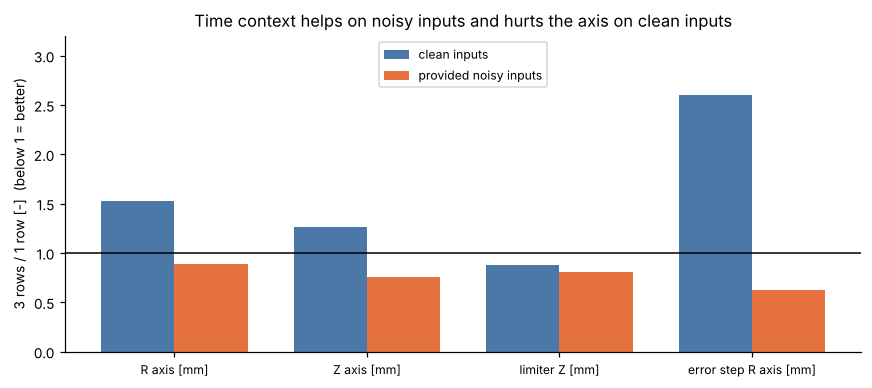

**Reading.** With noisy inputs three rows lower the radial axis error from 2.64 to 2.33 mm, the vertical from 2.01 to 1.51 mm and the error step from 1.84 to 1.15 mm: the history averages out the noise. With clean inputs the same window makes the axis worse (0.38 to 0.57 mm) and helps only the limiter Z (22.2 to 19.5 mm). The reason is not established: overfitting of the larger input layer and collinear stacked rows are two untested hypotheses. The window needs only past samples, but the 72-input network was **not timed**.

*Quoted from `results/ipp1-robustness-findings.md`:*

- One initialization and one noise realization per fold; the fold to fold SD is descriptive, not a confidence interval.
  Differences of a few percent (for example augmented against noisy training) are not established.
- Drift is a model of ours (linear per coil), not a measured drift of the real diagnostics. Amplitudes were fixed before the
  run and were not tuned on test data.
- Dropped inputs, a bigger network or tuned epochs were not tried here; numbers are for the baseline architecture.
- Epochs are fixed (60, augmented 30 on twice the rows), so the learning curve mixes less information with fewer updates.

In [9]:
tc = table(F_ROB, "3. Time context")
tc.columns = ["input", "window", "R axis [mm]", "Z axis [mm]", "limiter Z [mm]", "error step R axis [mm]"]
tc["window"] = tc["window"].map(num).astype(int); tc = tc.set_index(["input", "window"]).astype(float)
show(tc, P_R + "; window = number of consecutive rows given to the network")

rel = pd.concat({k: tc.loc[(k, 3)] / tc.loc[(k, 1)] for k in ("clean", "provided noisy")}, axis=1)
fig, ax = plt.subplots(figsize=(8, 3.6)); x = np.arange(len(rel)); w = 0.38
ax.bar(x - w/2, rel["clean"], w, label="clean inputs", color="#4c78a8"); ax.bar(x + w/2, rel["provided noisy"], w, label="provided noisy inputs", color="#e6733f")
ax.axhline(1, color="k", lw=1); ax.set_xticks(x); ax.set_xticklabels(rel.index, fontsize=8); ax.set_ylabel("3 rows / 1 row [-]  (below 1 = better)")
ax.set_ylim(0, 3.2); ax.set_title("Time context helps on noisy inputs and hurts the axis on clean inputs"); ax.legend(fontsize=8, loc="upper center"); plt.tight_layout(); plt.show()
display(Markdown(
    f"**Reading.** With noisy inputs three rows lower the radial axis error from {tc.loc[('provided noisy',1),'R axis [mm]']:.2f} to {tc.loc[('provided noisy',3),'R axis [mm]']:.2f} mm, the vertical from "
    f"{tc.loc[('provided noisy',1),'Z axis [mm]']:.2f} to {tc.loc[('provided noisy',3),'Z axis [mm]']:.2f} mm and the error step from {tc.loc[('provided noisy',1),'error step R axis [mm]']:.2f} to "
    f"{tc.loc[('provided noisy',3),'error step R axis [mm]']:.2f} mm: the history averages out the noise. With clean inputs the same window makes the axis worse "
    f"({tc.loc[('clean',1),'R axis [mm]']:.2f} to {tc.loc[('clean',3),'R axis [mm]']:.2f} mm) and helps only the limiter Z ({tc.loc[('clean',1),'limiter Z [mm]']:.1f} to {tc.loc[('clean',3),'limiter Z [mm]']:.1f} mm). "
    f"The reason is not established: overfitting of the larger input layer and collinear stacked rows are two untested hypotheses. The window needs only past samples, but the 72-input network was **not timed**."))
quote("\n".join(l for l in section(F_ROB, "Limits").splitlines()), F_ROB)

## 6. What these results change about the earlier verdicts

The latency of the network computation (notebook 05, `results/ipp1-latency.json`) was measured for the baseline network only (24 inputs; the weights do not change the timing). This notebook supplies the missing condition on
the input: the same network agrees closely with the reference reconstruction on clean signals and fails on noisy ones unless it is trained with noise.

In [10]:
lat = json.loads(read("ipp1-latency.json"))
ship = read("ipp1-latency-shipped.md")
ship_div, ship_lim = map(float, re.search(r"median (\d\.\d+) ms when the plasma is diverted.*?and (\d\.\d+) ms when", ship, re.S).groups())
one = lat["cpu_1_thread_single_sample"]
display(Markdown(
    f"**Real-time verdict, conditional.** The forward pass of the {lat['parameters']:,}-parameter baseline network takes a median of {one['median_ms']:.4f} ms on one thread of an {lat['cpu']} CPU "
    f"(p99.9 {one['p999_ms']:.3f} ms, slowest of 5,000 calls {one['max_ms']:.3f} ms); the machine was shared, with load average {lat['load_average_start'][0]:.1f} / {lat['load_average_start'][1]:.1f} / {lat['load_average_start'][2]:.1f} "
    f"(1, 5, 15 minutes) at the start, so tails are indicative and no worst-case guarantee is claimed. The budget is 1 to 10 ms. On a loaded machine or another CPU the median is 0.03 to 0.07 ms (notebook 05). **Not verified:** acquisition and integration of the coil signals, the worst case on a real-time system, "
    f"and accuracy on really noisy signals: a network trained on clean data gives {cn:.1f} mm on the radial axis on the provided noisy file, one trained with noise gives {nn:.1f} mm "
    f"(section 2). The shipped model (numpy path, clean inputs) takes a median of {ship_div:.4f} ms for a diverted and {ship_lim:.4f} ms for a limited plasma (`ipp1-latency-shipped.md`) but fails on noisy inputs (section 2.1); the 72-input time-context network was not timed."))

**Real-time verdict, conditional.** The forward pass of the 107,152-parameter baseline network takes a median of 0.0145 ms on one thread of an Apple M5 CPU (p99.9 0.081 ms, slowest of 5,000 calls 0.148 ms); the machine was shared, with load average 5.7 / 14.5 / 29.3 (1, 5, 15 minutes) at the start, so tails are indicative and no worst-case guarantee is claimed. The budget is 1 to 10 ms. On a loaded machine or another CPU the median is 0.03 to 0.07 ms (notebook 05). **Not verified:** acquisition and integration of the coil signals, the worst case on a real-time system, and accuracy on really noisy signals: a network trained on clean data gives 10.2 mm on the radial axis on the provided noisy file, one trained with noise gives 2.6 mm (section 2). The shipped model (numpy path, clean inputs) takes a median of 0.0154 ms for a diverted and 0.0274 ms for a limited plasma (`ipp1-latency-shipped.md`) but fails on noisy inputs (section 2.1); the 72-input time-context network was not timed.

In [11]:
missing, n_read, git_ok = tracked_check()
print(f"{n_read} results files read:", ", ".join(sorted(READ)))
print("all of them are tracked in git:", (not missing) if git_ok else "git not available here, cannot check")
assert not missing, missing

6 results files read: ipp1-data-checks.md, ipp1-final.md, ipp1-latency-shipped.md, ipp1-latency.json, ipp1-robustness-findings.md, ipp1-time.json
all of them are tracked in git: True


In [12]:
display(Markdown(f"""
## Answer

**The baseline network agrees closely with the reference reconstruction on clean signals and is not robust to noise unless it is trained with noise, and this has a price.** The provided noisy file is white noise (lag-1 autocorrelation {lag1}) with no measurable drift,
so every drift result is synthetic. A network trained on clean data differs from the reference reconstruction by {cc:.2f} mm on the radial axis on clean inputs and by {cn:.1f} mm on the noisy file ({cn/cc:.0f} times larger); trained with noise it gives
{nn:.1f} mm on noisy inputs and {nc:.1f} mm on clean ones. A synthetic drift adds about {drift_h:.0f} mm to the network trained with noise and {drift_c:.1f} mm to the clean-trained one. On the 30 kept-aside discharges (an easier set) the noise-trained baseline gives {ba:.1f} mm against {b:.1f} mm for the plain baseline on the noisy file,
and no single model wins on both kinds of input. The output is as smooth as the reference values only on clean inputs: on noisy inputs a clean-trained network varies {jit.loc['R_mag_axis'].iloc[1]:.1f} times (radial axis) more than the reference values, {jit.loc['R_mag_axis'].iloc[2]:.1f} times after training with noise.

**Amount of data.** With 30 training discharges the radial axis error is {r[30]:.2f} mm, with {lc.index[-1]} it is {r[119]:.2f} mm; the error roughly halves per doubling in the tested range, with the caveat of a fixed number of epochs, and we did not test beyond {lc.index[-1]} discharges.

**Time context.** Three consecutive samples help on noisy inputs (axis {tc.loc[('provided noisy',1),'R axis [mm]']:.2f} to {tc.loc[('provided noisy',3),'R axis [mm]']:.2f} mm) and hurt the axis on clean ones ({tc.loc[('clean',1),'R axis [mm]']:.2f} to {tc.loc[('clean',3),'R axis [mm]']:.2f} mm).
All of this is for the baseline network (the numbers are for noise we or the organizers added, not for real probe failures), one initialization per fold, and the real-time verdict stays conditional (section 6).
"""))


## Answer

**The baseline network agrees closely with the reference reconstruction on clean signals and is not robust to noise unless it is trained with noise, and this has a price.** The provided noisy file is white noise (lag-1 autocorrelation -0.004) with no measurable drift,
so every drift result is synthetic. A network trained on clean data differs from the reference reconstruction by 0.38 mm on the radial axis on clean inputs and by 10.2 mm on the noisy file (27 times larger); trained with noise it gives
2.6 mm on noisy inputs and 2.2 mm on clean ones. A synthetic drift adds about 1 mm to the network trained with noise and 4.7 mm to the clean-trained one. On the 30 kept-aside discharges (an easier set) the noise-trained baseline gives 2.4 mm against 9.2 mm for the plain baseline on the noisy file,
and no single model wins on both kinds of input. The output is as smooth as the reference values only on clean inputs: on noisy inputs a clean-trained network varies 8.4 times (radial axis) more than the reference values, 1.7 times after training with noise.

**Amount of data.** With 30 training discharges the radial axis error is 1.47 mm, with 119 it is 0.38 mm; the error roughly halves per doubling in the tested range, with the caveat of a fixed number of epochs, and we did not test beyond 119 discharges.

**Time context.** Three consecutive samples help on noisy inputs (axis 2.64 to 2.33 mm) and hurt the axis on clean ones (0.38 to 0.57 mm).
All of this is for the baseline network (the numbers are for noise we or the organizers added, not for real probe failures), one initialization per fold, and the real-time verdict stays conditional (section 6).
